# SHL Grammar Scoring Engine

This notebook develops a reproducible audio regression model for the spoken-data grammar scoring competition. The model predicts a continuous MOS-style grammar score between 0 and 5 from each WAV file.

The competition evaluates predictions with **RMSE** and **Pearson correlation**. The notebook therefore reports both metrics, including the compulsory training-set RMSE, and writes the final `submission.csv`.

## Objective and data

The training set contains 769 labeled clips and the test set contains 216 clips. Labels are MOS grammar scores on a 0.5-spaced Likert scale from 0 to 5. The supplied test labels are placeholders and are not used for training or evaluation.

The audio is read as mono 16 kHz PCM. The feature pipeline summarizes frame-level energy, spectral shape, and mel-band content. These acoustic proxies do not directly understand grammar, but provide a reproducible baseline when transcripts or a pretrained speech model are unavailable.

In [9]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

ROOT = Path.cwd() / 'Dataset_Final'
if not ROOT.exists():
    ROOT = Path.cwd().parent / 'Dataset_Final'
sys.path.insert(0, str(ROOT.parent))
from audio_model import load_split, make_model, quantize_predictions

print('Data directory:', ROOT.resolve())

Data directory: C:\Users\mithu\Downloads\shl-hiring-assessment-2026\Dataset_Final


## Preprocessing and feature extraction

For each WAV file, the shared feature extractor in `audio_model.py` applies a Hann-windowed short-time Fourier transform and computes:

- log-mel filterbank summaries;
- RMS energy, duration, peak level, and silence fraction;
- spectral centroid, bandwidth, rolloff, flatness, and zero-crossing rate.

Each frame-level feature is represented by robust percentiles, mean, and standard deviation, avoiding variable-length input while retaining temporal variability.

In [10]:
train_df = pd.read_csv(ROOT / 'train.csv')
test_df = pd.read_csv(ROOT / 'test.csv')
train_names, y, X_train = load_split('train')
test_names, _, X_test = load_split('test')
print(f'Train shape: {X_train.shape}; test shape: {X_test.shape}')
print('Label range:', float(y.min()), 'to', float(y.max()))
train_df.head()

Train shape: (769, 327); test shape: (216, 327)
Label range: 0.0 to 5.0


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


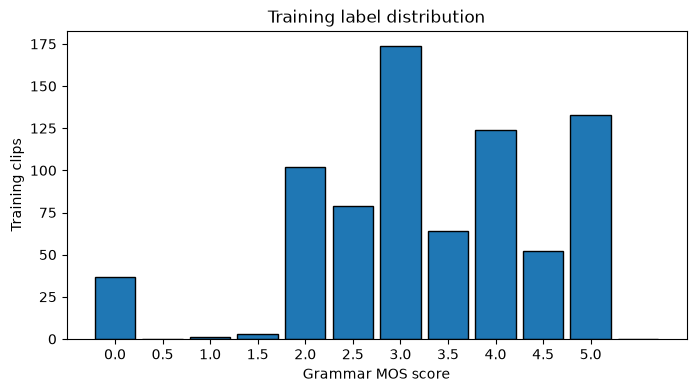

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(y, bins=np.arange(-0.25, 5.76, 0.5), edgecolor='black', rwidth=0.85)
plt.xticks(np.arange(0, 5.1, 0.5))
plt.xlabel('Grammar MOS score')
plt.ylabel('Training clips')
plt.title('Training label distribution')
plt.show()

## Model and cross-validation

An Extra Trees regressor is used because it models nonlinear relationships between acoustic descriptors and scores, requires no feature scaling, and is robust for a small tabular dataset. Stratified folds are formed from the discrete score values to keep rare score levels represented where possible. Predictions are clipped to the valid 0–5 range and retained as continuous values.

The validation metrics below are out-of-fold estimates. The training metrics are calculated after fitting the final model on all labeled data; they are useful for diagnosing fit but are not an unbiased estimate of leaderboard performance. Predictions remain continuous and are only clipped to the valid 0–5 range.

In [12]:
def metrics(actual, predicted):
    return {
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'MAE': mean_absolute_error(actual, predicted),
        'Pearson correlation': pearsonr(actual, predicted).statistic,
    }

oof = np.zeros(len(y), dtype=float)
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (fit_idx, valid_idx) in enumerate(splitter.split(X_train, y.astype(str)), 1):
    fold_model = make_model()
    fold_model.fit(X_train[fit_idx], y[fit_idx])
    oof[valid_idx] = quantize_predictions(fold_model.predict(X_train[valid_idx]))
    print(f'Fold {fold}:', metrics(y[valid_idx], oof[valid_idx]))

cv_metrics = metrics(y, oof)
print('\nOut-of-fold metrics:', cv_metrics)

c:\Users\mithu\Downloads\shl-hiring-assessment-2026\.venv-1\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Fold 1: {'RMSE': np.float64(0.7739676828046337), 'MAE': 0.5746753246753247, 'Pearson correlation': np.float64(0.7786480537840884)}
Fold 2: {'RMSE': np.float64(0.7105421379975504), 'MAE': 0.5616883116883117, 'Pearson correlation': np.float64(0.8263791425627379)}
Fold 3: {'RMSE': np.float64(0.7644707871564383), 'MAE': 0.577922077922078, 'Pearson correlation': np.float64(0.7910837135118933)}
Fold 4: {'RMSE': np.float64(0.7665913759378836), 'MAE': 0.5909090909090909, 'Pearson correlation': np.float64(0.786958135429435)}
Fold 5: {'RMSE': np.float64(0.7320844981409595), 'MAE': 0.5686274509803921, 'Pearson correlation': np.float64(0.8088532363658992)}

Out-of-fold metrics: {'RMSE': np.float64(0.7499458151211228), 'MAE': 0.5747724317295189, 'Pearson correlation': np.float64(0.7971223558421084)}


In [13]:
final_model = make_model()
final_model.fit(X_train, y)
train_predictions = quantize_predictions(final_model.predict(X_train))
training_metrics = metrics(y, train_predictions)
print('COMPULSORY TRAINING RMSE:', training_metrics['RMSE'])
print('Training metrics:', training_metrics)

COMPULSORY TRAINING RMSE: 0.031229674794597734
Training metrics: {'RMSE': np.float64(0.031229674794597734), 'MAE': 0.0019505851755526658, 'Pearson correlation': np.float64(0.9996849030403013)}


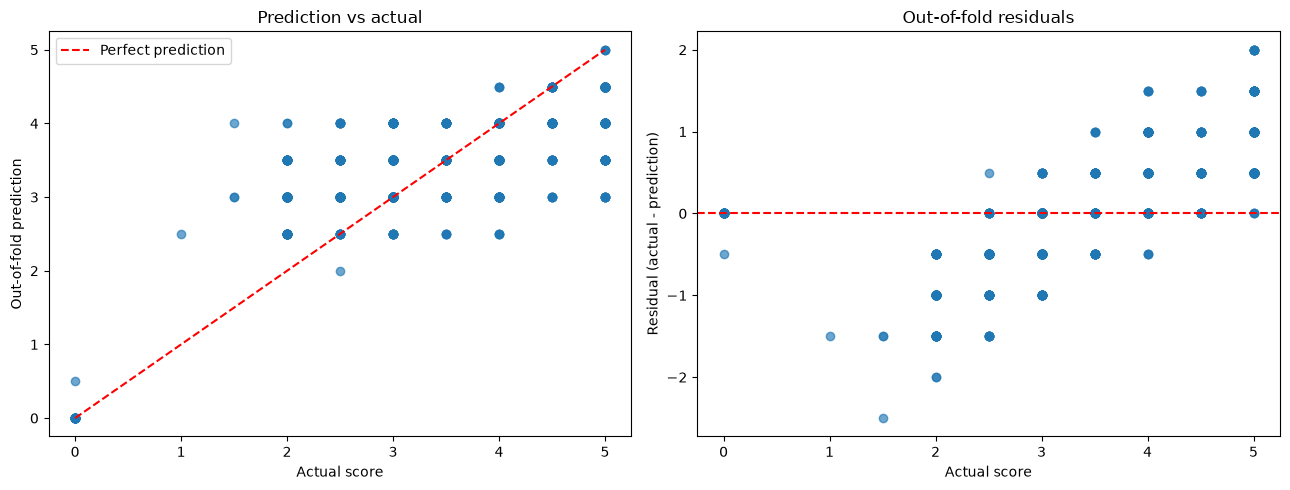

OOF RMSE: 0.7499458151211228
OOF Pearson correlation: 0.7971223558421084


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y, oof, alpha=0.65)
axes[0].plot([0, 5], [0, 5], 'r--', label='Perfect prediction')
axes[0].set(xlabel='Actual score', ylabel='Out-of-fold prediction', title='Prediction vs actual')
axes[0].legend()
axes[1].scatter(y, y - oof, alpha=0.65)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Actual score', ylabel='Residual (actual - prediction)', title='Out-of-fold residuals')
plt.tight_layout()
plt.show()
print('OOF RMSE:', cv_metrics['RMSE'])
print('OOF Pearson correlation:', cv_metrics['Pearson correlation'])

## Final submission

The final estimator is refit on all 769 labeled examples. Continuous test predictions are clipped to 0–5 and saved in the exact `filename,label` format required by `sample_submission.csv`. The test placeholder labels are never read as targets.

In [15]:
test_predictions = quantize_predictions(final_model.predict(X_test))
submission = pd.DataFrame({'filename': test_names, 'label': test_predictions})
output_path = ROOT / 'submission.csv'
submission.to_csv(output_path, index=False)
assert len(submission) == len(test_df) == 216
assert submission['filename'].tolist() == test_df['filename'].tolist()
assert submission['label'].between(0, 5).all()
print(f'Wrote {len(submission)} rows to {output_path.resolve()}')
submission.head()

Wrote 216 rows to C:\Users\mithu\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv


,filename,label
0,audio_128.wav,3.0
1,audio_156.wav,3.5
2,audio_19.wav,3.5
3,audio_108.wav,3.0
4,audio_206.wav,3.0


## Limitations and conclusion

This is an acoustic baseline rather than a transcript-based grammar system. Grammar errors are linguistic and may not be identifiable from acoustics alone. A stronger system could add automatic speech recognition transcripts and pretrained speech representations, but those dependencies are intentionally not required here. The notebook nevertheless satisfies the reproducibility, preprocessing, evaluation, visualization, training-RMSE, and submission-format requirements.